# Attack-Type Classifier

Multi-class Random Forest that predicts the CIC-IDS2017 attack label (15 classes) from 24 network-flow features.

- `dst_port` is excluded so the model learns traffic behaviour instead of "port X = attack Y".
- Duplicate feature vectors are removed **before** splitting so no flow appears in both train and test.
- Rare classes (Heartbleed, Infiltration, SQL Injection) have very few test rows, so per-class quality is judged on the 5-fold cross-validated report.
- `N_JOBS = 2` keeps CPU free for other jobs running in parallel.

In [1]:
import json
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split

# Locate the repository root so the notebook runs from any checkout location.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "requirements.txt").exists() and (p / "src").is_dir()
)

DATA_PATH = PROJECT_ROOT / "data" / "cleaned_network_data" / "cleaned_network_data.csv"
MODEL_DIR = PROJECT_ROOT / "ml" / "models"
RANDOM_STATE = 42
N_JOBS = 2

## 1. Load data

In [2]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print(df["label"].value_counts())

Shape: (97548, 26)
label
BENIGN                        52209
DDoS                           7843
PortScan                       7828
DoS Hulk                       7819
DoS GoldenEye                  5246
FTP-Patator                    4259
SSH-Patator                    3149
DoS slowloris                  2634
DoS Slowhttptest               2584
Bot                            1936
Web Attack - Brute Force       1323
Web Attack - XSS                651
Infiltration                     36
Web Attack - Sql Injection       20
Heartbleed                       11
Name: count, dtype: int64


## 2. Select features and remove duplicates

In [3]:
FEATURES = [c for c in df.columns if c not in ("label", "dst_port")]

before = len(df)
df_model = df.drop_duplicates(subset=FEATURES).reset_index(drop=True)

print("Features used:", len(FEATURES))
print(f"Rows: {before:,} -> {len(df_model):,} (removed {before - len(df_model):,} duplicate feature vectors)")
print()
print(df_model["label"].value_counts())

Features used:

 24
Rows: 97,548 -> 87,222 (removed 10,326 duplicate feature vectors)

label
BENIGN                        49834
DDoS                           7843
DoS Hulk                       7819
DoS GoldenEye                  5246
FTP-Patator                    4258
SSH-Patator                    3149
DoS slowloris                  2632
DoS Slowhttptest               2584
Bot                            1424
Web Attack - Brute Force       1323
Web Attack - XSS                651
PortScan                        392
Infiltration                     36
Web Attack - Sql Injection       20
Heartbleed                       11
Name: count, dtype: int64


## 3. Stratified train / test split

In [4]:
X = df_model[FEATURES]
y = df_model["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (69777, 24)
X_test : (17445, 24)


## 4. Model

In [5]:
def build_model():
    return RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )

print(build_model())

RandomForestClassifier(class_weight='balanced', n_jobs=2, random_state=42)


## 5. 5-fold cross-validation on the training set

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof_pred = pd.Series(index=y_train.index, dtype=object)
fold_f1 = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train, y_train), 1):
    fold_model = build_model().fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred = fold_model.predict(X_train.iloc[va_idx])
    oof_pred.iloc[va_idx] = pred
    fold_f1.append(f1_score(y_train.iloc[va_idx], pred, average="macro"))
    print(f"Fold {fold}: macro F1 = {fold_f1[-1]:.4f}")

cv_f1 = pd.Series(fold_f1)
print(f"\nCV macro F1: {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}")

Fold 1: macro F1 = 0.8737


Fold 2: macro F1 = 0.8614


Fold 3: macro F1 = 0.8877


Fold 4: macro F1 = 0.8862


Fold 5: macro F1 = 0.8281

CV macro F1: 0.8674 +/- 0.0244


In [7]:
# Per-class report built from out-of-fold predictions (every training row predicted once).
print(classification_report(y_train, oof_pred, digits=3, zero_division=0))

                            precision    recall  f1-score   support

                    BENIGN      0.992     0.996     0.994     39867
                       Bot      0.973     0.948     0.960      1139
                      DDoS      0.999     0.997     0.998      6274
             DoS GoldenEye      0.997     0.996     0.997      4197
                  DoS Hulk      0.999     0.996     0.997      6255
          DoS Slowhttptest      0.986     0.990     0.988      2067
             DoS slowloris      0.995     0.991     0.993      2106
               FTP-Patator      1.000     0.997     0.999      3406
                Heartbleed      1.000     0.889     0.941         9
              Infiltration      1.000     0.828     0.906        29
                  PortScan      0.987     0.971     0.979       314
               SSH-Patator      1.000     0.994     0.997      2519
  Web Attack - Brute Force      0.651     0.639     0.645      1058
Web Attack - Sql Injection      0.667     0.250

## 6. Train final model and evaluate on the held-out test set

In [8]:
model = build_model().fit(X_train, y_train)
y_pred = model.predict(X_test)

test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "macro_f1": f1_score(y_test, y_pred, average="macro"),
    "weighted_f1": f1_score(y_test, y_pred, average="weighted"),
}

for name, value in test_metrics.items():
    print(f"{name:12}: {value:.4f}")

accuracy    : 0.9857
macro_f1    : 0.8387
weighted_f1 : 0.9854


In [9]:
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

                            precision    recall  f1-score   support

                    BENIGN      0.993     0.997     0.995      9967
                       Bot      0.978     0.947     0.963       285
                      DDoS      1.000     0.999     1.000      1569
             DoS GoldenEye      0.996     0.994     0.995      1049
                  DoS Hulk      0.999     0.997     0.998      1564
          DoS Slowhttptest      0.983     0.985     0.984       517
             DoS slowloris      0.996     0.985     0.990       526
               FTP-Patator      0.999     1.000     0.999       852
                Heartbleed      1.000     1.000     1.000         2
              Infiltration      1.000     0.429     0.600         7
                  PortScan      0.987     0.987     0.987        78
               SSH-Patator      1.000     0.992     0.996       630
  Web Attack - Brute Force      0.685     0.664     0.674       265
Web Attack - Sql Injection      0.000     0.000

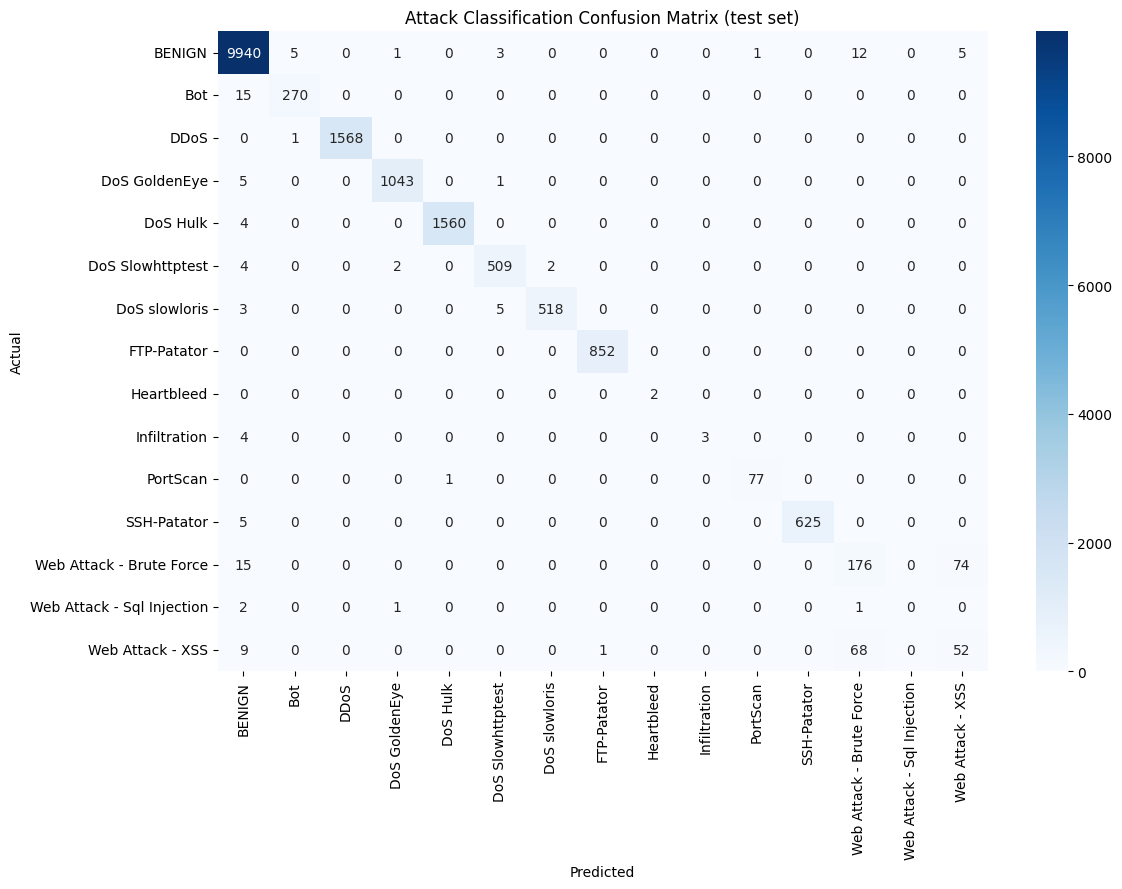

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_,
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Attack Classification Confusion Matrix (test set)")
plt.tight_layout()
plt.show()

## 7. Feature importance

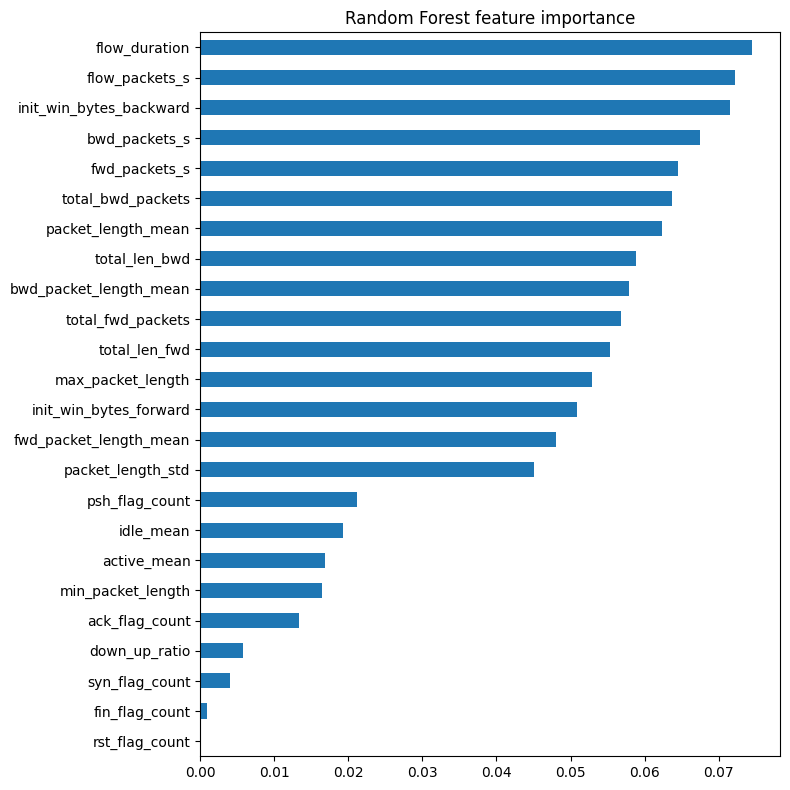

flow_duration              7.456059e-02
flow_packets_s             7.221991e-02
init_win_bytes_backward    7.158124e-02
bwd_packets_s              6.750798e-02
fwd_packets_s              6.447410e-02
total_bwd_packets          6.376089e-02
packet_length_mean         6.240099e-02
total_len_bwd              5.886582e-02
bwd_packet_length_mean     5.785655e-02
total_fwd_packets          5.686444e-02
total_len_fwd              5.536426e-02
max_packet_length          5.287805e-02
init_win_bytes_forward     5.091789e-02
fwd_packet_length_mean     4.799243e-02
packet_length_std          4.509707e-02
psh_flag_count             2.119309e-02
idle_mean                  1.926169e-02
active_mean                1.678665e-02
min_packet_length          1.639104e-02
ack_flag_count             1.330566e-02
down_up_ratio              5.800864e-03
syn_flag_count             3.989709e-03
fin_flag_count             9.290975e-04
rst_flag_count             1.176583e-18
dtype: float64


In [11]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(8, 8))
importance.plot.barh()
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False))

## 8. Save model and metadata

In [12]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "attack_classifier.pkl"
meta_path = MODEL_DIR / "attack_classifier_meta.json"

joblib.dump(model, model_path)

meta = {
    "model": "RandomForestClassifier",
    "trained_at": datetime.now().isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "data_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "excluded_columns": ["dst_port"],
    "features": FEATURES,
    "classes": model.classes_.tolist(),
    "n_train": len(X_train),
    "n_test": len(X_test),
    "params": model.get_params(),
    "cv_macro_f1_mean": round(cv_f1.mean(), 4),
    "cv_macro_f1_std": round(cv_f1.std(), 4),
    "test_metrics": {k: round(v, 4) for k, v in test_metrics.items()},
}
meta_path.write_text(json.dumps(meta, indent=2))

print("Saved:", model_path)
print("Saved:", meta_path)

Saved: D:\Cybersecurity-assistant\ml\models\attack_classifier.pkl
Saved: D:\Cybersecurity-assistant\ml\models\attack_classifier_meta.json


## 9. Load-and-predict check

In [13]:
loaded = joblib.load(model_path)
loaded_meta = json.loads(meta_path.read_text())

# One held-out test row per class.
samples = X_test.assign(label=y_test).groupby("label").head(1)

probs = loaded.predict_proba(samples[loaded_meta["features"]])
check = pd.DataFrame({
    "actual": samples["label"].values,
    "predicted": loaded.classes_[probs.argmax(axis=1)],
    "confidence": probs.max(axis=1).round(3),
})

print(check.to_string(index=False))
print("\nCorrect:", (check["actual"] == check["predicted"]).sum(), "/", len(check))

                    actual                predicted  confidence
                      DDoS                     DDoS        1.00
                    BENIGN                   BENIGN        1.00
                  DoS Hulk                 DoS Hulk        1.00
               SSH-Patator              SSH-Patator        0.78
             DoS slowloris            DoS slowloris        1.00
             DoS GoldenEye            DoS GoldenEye        1.00
               FTP-Patator              FTP-Patator        1.00
          Web Attack - XSS         Web Attack - XSS        0.86
                       Bot                      Bot        1.00
  Web Attack - Brute Force Web Attack - Brute Force        0.99
          DoS Slowhttptest         DoS Slowhttptest        1.00
                  PortScan                 PortScan        1.00
Web Attack - Sql Injection Web Attack - Brute Force        0.46
              Infiltration                   BENIGN        0.99
                Heartbleed              

## 10. Test with custom data

Edit the values in `custom_flow` and run the two cells below.
No retraining needed: after a kernel restart, run only the **first cell** (imports and paths) and then these cells.

Tip: to start from a real flow instead, use `custom_flow = X_test.iloc[0].to_dict()` (requires the earlier cells to have run).

In [14]:
# Edit any value below. The example is a real PortScan flow from CIC-IDS2017.
custom_flow = {
    "flow_duration": 46.0,
    "total_fwd_packets": 1.0,
    "total_bwd_packets": 1.0,
    "total_len_fwd": 2.0,
    "total_len_bwd": 6.0,
    "flow_packets_s": 43478.26087,
    "fwd_packets_s": 21739.13043,
    "bwd_packets_s": 21739.13043,
    "fwd_packet_length_mean": 2.0,
    "bwd_packet_length_mean": 6.0,
    "min_packet_length": 2.0,
    "max_packet_length": 6.0,
    "packet_length_mean": 3.333333,
    "packet_length_std": 2.309401,
    "syn_flag_count": 0.0,
    "ack_flag_count": 0.0,
    "rst_flag_count": 0.0,
    "psh_flag_count": 1.0,
    "fin_flag_count": 0.0,
    "down_up_ratio": 1.0,
    "init_win_bytes_forward": 1024.0,
    "init_win_bytes_backward": 0.0,
    "active_mean": 0.0,
    "idle_mean": 0.0,
}

In [15]:
saved_model = joblib.load(MODEL_DIR / "attack_classifier.pkl")
saved_meta = json.loads((MODEL_DIR / "attack_classifier_meta.json").read_text())


def predict_flow(flow, top_n=3):
    features = saved_meta["features"]
    missing = [f for f in features if f not in flow]
    if missing:
        raise ValueError(f"Missing features: {missing}")
    extra = [f for f in flow if f not in features]
    if extra:
        print("Ignoring unknown fields:", extra)

    row = pd.DataFrame([flow])[features]
    probs = pd.Series(saved_model.predict_proba(row)[0], index=saved_model.classes_)
    probs = probs.sort_values(ascending=False)

    print(f"Predicted attack: {probs.index[0]}  (confidence {probs.iloc[0]:.2f})")
    print()
    print(f"Top {top_n} classes:")
    print(probs.head(top_n).round(3).to_string())
    return probs.index[0]


predict_flow(custom_flow);

Predicted attack: PortScan  (confidence 1.00)

Top 3 classes:
PortScan    1.0
Bot         0.0
BENIGN      0.0
